In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# تنظیمات نمایش
pd.set_option('display.max_columns', None)
import warnings
warnings.filterwarnings('ignore')

print("Libraries Loaded Successfully!")

Libraries Loaded Successfully!


In [8]:
# بارگذاری دیتاست

file_path = 'XAU_15m_data.csv'
df = pd.read_csv(file_path, delimiter=';')

# تبدیل تاریخ
df['Date'] = pd.to_datetime(df['Date'], format='%Y.%m.%d %H:%M')
df = df.sort_values('Date').reset_index(drop=True)

# --- Feature Engineering (ساخت ویژگی‌ها) ---

# 1. محاسبه ATR (برای سنجش نوسان)
df['HL'] = df['High'] - df['Low']
df['HC'] = abs(df['High'] - df['Close'].shift(1))
df['LC'] = abs(df['Low'] - df['Close'].shift(1))
df['TR'] = df[['HL', 'HC', 'LC']].max(axis=1)
df['ATR'] = df['TR'].rolling(window=14).mean()

# 2. محاسبه RSI
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))

# 3. ویژگی‌های کندلی
df['Body_Size'] = abs(df['Close'] - df['Open'])
df['Upper_Shadow'] = df['High'] - df[['Open', 'Close']].max(axis=1)
df['Hour'] = df['Date'].dt.hour  # ساعت بازار (خیلی مهمه)

# تشخیص کندل نزولی
df['Is_Bearish'] = np.where(df['Close'] < df['Open'], 1, 0)

# حذف مقادیر خالی (NaN)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print(f" Data Prepared. Shape: {df.shape}")
df.tail()

 Data Prepared. Shape: (487951, 16)


,Date,Open,High,Low,Close,Volume,HL,HC,LC,TR,ATR,RSI,Body_Size,Upper_Shadow,Hour,Is_Bearish
487946,2025-12-01 03:15:00,4228.27,4239.05,4224.30,4238.37,15233,14.75,10.82,3.93,14.75,48.387857,98.709836,10.10,0.68,3,0
487947,2025-12-01 03:30:00,4238.41,4243.72,4234.52,4241.24,11571,9.20,5.35,3.85,9.20,48.798571,99.009901,2.83,2.48,3,0
487948,2025-12-01 03:45:00,4241.19,4255.95,4236.91,4255.04,10933,19.04,14.71,4.33,19.04,50.060000,99.030790,13.85,0.91,3,0
487949,2025-12-01 04:00:00,4254.98,4256.34,4245.38,4248.17,11052,10.96,1.30,9.66,10.96,50.725714,98.050630,6.81,1.36,4,1
487950,2025-12-01 04:15:00,4248.22,4248.73,4245.90,4246.38,1847,2.83,0.56,2.27,2.83,50.863571,97.772081,1.84,0.51,4,1


In [9]:
print(" Finding Peaks & Generating Targets...")

# پارامترهای تشخیص قله
PEAK_ORDER = 5  # پنج کندل چپ و راست باید پایینتر باشن

# پیدا کردن ایندکس قله‌ها (P0)
peaks_indices = argrelextrema(df['High'].values, np.greater_equal, order=PEAK_ORDER)[0]
dataset = []

for idx in peaks_indices:
    # بررسی مرزهای دیتا
    if idx < 50 or idx + 100 >= len(df): continue
    
    # --- مشخصات P0 (سقف) ---
    p0_idx = idx
    p0_high = df.loc[p0_idx, 'High']
    
    # --- مشخصات P1 (نقطه ورود - 2 کندل بعد) ---
    p1_idx = idx + 2
    p1 = df.loc[p1_idx]
    
    if pd.isna(p1['ATR']): continue

    # ویژگی‌هایی که مدل می‌بیند (Input Features)
    features = {
        'ATR': p1['ATR'],
        'RSI': p1['RSI'],
        'Hour': p1['Hour'],
        'Dist_P0_P1_ATR': (p0_high - p1['Close']) / p1['ATR'], # فاصله تا استاپ
        'P1_Body_ATR': p1['Body_Size'] / p1['ATR'],
        'P1_Upper_Shadow_ATR': p1['Upper_Shadow'] / p1['ATR'],
        'P1_Is_Bearish': p1['Is_Bearish'],
        
        # اطلاعات کمکی برای بک‌تست (اینها به مدل داده نمیشه)
        'P1_Close': p1['Close'],
        'P0_High': p0_high,
        'P1_Index': p1_idx,
        'Date': p1['Date']
    }
    
    # --- تعیین متغیر هدف (Target) با نگاه به آینده ---
    
    # فرض کنیم الان وارد شدیم (ریسک به ریوارد 1 به 1)
    risk_dist = p0_high - p1['Close']
    target_price = p1['Close'] - risk_dist 
    
    # بررسی 50 کندل آینده
    future = df.loc[p1_idx+1 : p1_idx+50]
    
    # کی استاپ میخوره؟ کی تارگت؟
    sl_hit = future[future['High'] > p0_high]
    tp_hit = future[future['Low'] < target_price]
    
    first_sl_idx = sl_hit.index[0] if not sl_hit.empty else 999999
    first_tp_idx = tp_hit.index[0] if not tp_hit.empty else 999999
    
    # منطق تنبیه (Penalty Logic):
    if first_tp_idx < first_sl_idx:
        # ✅ ترید برنده بوده:
        # پس آلفای کوچکی بهش اختصاص میدیم تا مدل یاد بگیره وارد بشه.
        # 0.3 یعنی 30 درصد ATR پایینتر اردر بذار
        features['Target_Alpha_Ratio'] = 0.3 
    else:
        # ❌ ترید بازنده بوده (یا اصلا به تارگت نرسیده):
        # پس آلفای وحشتناک بزرگ میدیم تا مدل یاد بگیره وارد نشه.
        # 5.0 یعنی برو قیمت پرت بذار که اردر فعال نشه
        features['Target_Alpha_Ratio'] = 5.0 
        
    dataset.append(features)

ml_data = pd.DataFrame(dataset)
print(f" Labeling Done! Total Setup Samples: {len(ml_data)}")
ml_data.head()

 Finding Peaks & Generating Targets...
 Labeling Done! Total Setup Samples: 34719


,ATR,RSI,Hour,Dist_P0_P1_ATR,P1_Body_ATR,P1_Upper_Shadow_ATR,P1_Is_Bearish,P1_Close,P0_High,P1_Index,Date,Target_Alpha_Ratio
0,0.485714,57.142857,6,1.029412,0.000000,0.617647,0,382.8,383.3,52,2004-06-14 06:30:00,5.0
1,0.485714,46.428571,9,2.058824,1.029412,0.000000,0,382.8,383.8,63,2004-06-14 09:15:00,5.0
2,0.771429,67.164179,15,1.944444,0.259259,0.000000,0,384.3,385.8,86,2004-06-14 15:00:00,0.3
3,0.850000,40.425532,19,0.823529,0.000000,0.235294,0,383.1,383.8,104,2004-06-14 19:30:00,0.3
4,0.457143,50.000000,22,0.000000,0.000000,0.000000,0,383.1,383.1,115,2004-06-14 22:15:00,0.3


In [10]:
# تقسیم داده به آموزش (80%) و تست (20%) به صورت زمانی
split = int(len(ml_data) * 0.8)
train_df = ml_data.iloc[:split]
test_df = ml_data.iloc[split:].copy()

# ستون‌های ورودی مدل (X)
X_cols = ['ATR', 'RSI', 'Hour', 'Dist_P0_P1_ATR', 'P1_Body_ATR', 'P1_Upper_Shadow_ATR']
# ستون هدف (y)
y_col = 'Target_Alpha_Ratio'

print(" Training Gradient Boosting Model...")

model = GradientBoostingRegressor(
    n_estimators=100,      # تعداد درخت‌ها
    max_depth=4,           # عمق درخت‌ها
    learning_rate=0.05,    # سرعت یادگیری
    random_state=42
)

model.fit(train_df[X_cols], train_df[y_col])

print(" Model Trained Successfully!")

# نمایش اهمیت ویژگی‌ها
importance = pd.DataFrame({
    'Feature': X_cols,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n Feature Importance:")
print(importance)

 Training Gradient Boosting Model...
 Model Trained Successfully!

 Feature Importance:
               Feature  Importance
3       Dist_P0_P1_ATR    0.665917
2                 Hour    0.212108
1                  RSI    0.046710
0                  ATR    0.028323
5  P1_Upper_Shadow_ATR    0.025457
4          P1_Body_ATR    0.021485


In [11]:
# --- 1. پیش‌بینی روی دیتای تست ---
# مدل برای هر موقعیت یک "آلفا ضریب" پیشنهاد میده
test_df['Predicted_Ratio'] = model.predict(test_df[X_cols])

# --- 2. حلقه شبیه‌سازی ---
capital = 10000       # سرمایه اولیه 10 هزار دلار
risk_per_trade = 100  # ریسک ثابت 100 دلار در هر ترید
balance_history = [capital]
wins = 0
losses = 0
filtered_count = 0

print(" Running Backtest...")

for idx, row in test_df.iterrows():
    # محاسبه آلفای پیشنهادی به دلار
    predicted_ratio = row['Predicted_Ratio']
    
    #  فیلتر هوشمند:
    # اگر مدل عددی بزرگتر از 1.5 داد، یعنی تشخیص داده این ترید ریسکش بالاست (شبیه بازنده‌هاست)
    # پس ما اصلا اردر نمیذاریم (یا اردر رو جایی میذاریم که فعال نمیشه)
    if predicted_ratio > 1.5:
        filtered_count += 1
        balance_history.append(capital)
        continue 

    # محاسبه قیمت ورود (Sell Stop)
    alpha_usd = predicted_ratio * row['ATR']
    # یک حداقل آلفا هم برای نویزگیری میذاریم (0.2)
    if alpha_usd < 0.2 * row['ATR']: alpha_usd = 0.2 * row['ATR']
    
    entry_price = row['P1_Close'] - alpha_usd
    stop_loss = row['P0_High']
    
    # چک منطقی (ورود نباید بالای استاپ باشه)
    if entry_price >= stop_loss:
        continue
        
    # تارگت (ریسک به ریوارد 1 به 1)
    risk = stop_loss - entry_price
    target = entry_price - risk
    
    # --- بررسی نتیجه در آینده ---
    p1_idx = int(row['P1_Index'])
    future = df.loc[p1_idx+1 : p1_idx+100]
    
    outcome = 0 # 0: فعال نشد, 1: سود, -1: ضرر
    filled = False
    
    for i, candle in future.iterrows():
        # 1. آیا اردر فعال شد؟
        if not filled:
            if candle['Low'] <= entry_price:
                filled = True
                # چک بدشانسی (استاپ در همان کندل)
                if candle['High'] >= stop_loss:
                    outcome = -1
                    break
        
        # 2. مدیریت پوزیشن باز
        if filled:
            if candle['High'] >= stop_loss:
                outcome = -1 # استاپ خورد
                break
            if candle['Low'] <= target:
                outcome = 1 # تارگت خورد
                break
    
    # آپدیت حساب
    if outcome == 1:
        capital += risk_per_trade
        wins += 1
    elif outcome == -1:
        capital -= risk_per_trade
        losses += 1
        
    balance_history.append(capital)

print(" Backtest Finished.")

 Running Backtest...
 Backtest Finished.



 FINAL STRATEGY REPORT
Total Opportunities Seen: 6944
Filtered by AI (Avoided): 5281
Trades Taken:             1558
Winning Trades:           864
Losing Trades:            694
-----------------------------------
Win Rate:                 55.46%
Net Profit:               $17000
Final Balance:            $27000.00


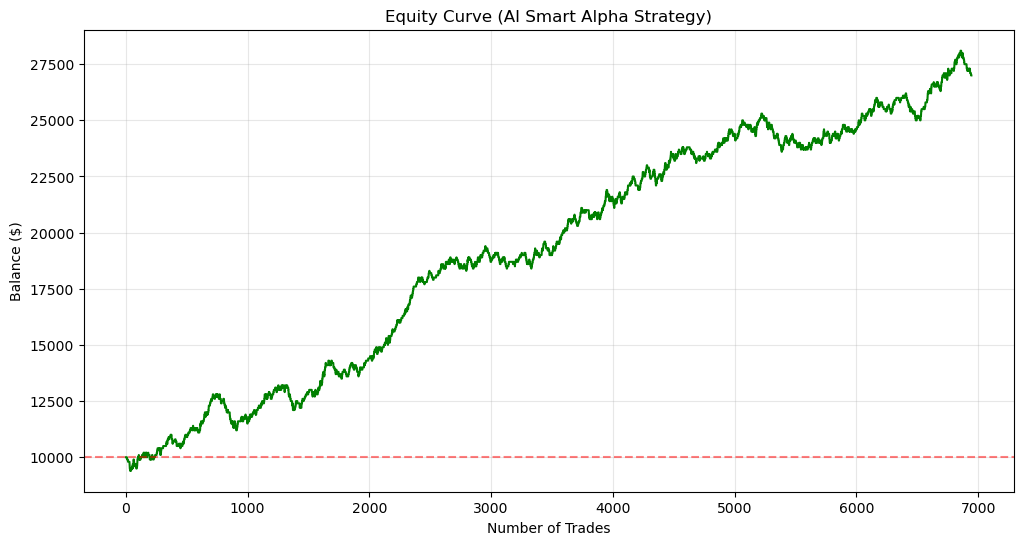

In [12]:
total_trades = wins + losses
win_rate = (wins / total_trades * 100) if total_trades > 0 else 0
net_profit = capital - 10000

print("\n" + "="*35)
print(" FINAL STRATEGY REPORT")
print("="*35)
print(f"Total Opportunities Seen: {len(test_df)}")
print(f"Filtered by AI (Avoided): {filtered_count}")
print(f"Trades Taken:             {total_trades}")
print(f"Winning Trades:           {wins}")
print(f"Losing Trades:            {losses}")
print("-" * 35)
print(f"Win Rate:                 {win_rate:.2f}%")
print(f"Net Profit:               ${net_profit}")
print(f"Final Balance:            ${capital:.2f}")
print("="*35)

# رسم نمودار اکوئیتی
plt.figure(figsize=(12, 6))
plt.plot(balance_history, color='green', linewidth=1.5)
plt.title('Equity Curve (AI Smart Alpha Strategy)')
plt.xlabel('Number of Trades')
plt.ylabel('Balance ($)')
plt.axhline(y=10000, color='r', linestyle='--', alpha=0.5) # خط سرمایه اولیه
plt.grid(True, alpha=0.3)
plt.show()